# Pós-Experimento em Modo Somente-Leitura: LaTeX, SVG e Conferências

Demonstramos o desacoplamento completo: após salvar um experimento, carregamos tudo em **modo somente-leitura** (`load_experiment_artifacts_readonly`), exibimos a tabela em Markdown + **LaTeX `booktabs`**, renderizamos o gráfico **SVG** e inspecionamos o pacote `reduced_no_raw_data` com checksums SHA-256.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## 1. Execução Prévia do Experimento Base (Simulando Servidor)

In [3]:
from pathlib import Path
import tempfile
import numpy as np

from experimental_ml.core.enums import MetricDirection, TaskType
from experimental_ml.data import (
    DatasetSchemaSpec,
    create_preparation_plan,
    load_dataset,
    profile_dataset,
    sanitize_dataset,
)
from experimental_ml.features import FeatureScenario, ScenarioMode
from experimental_ml.models import DummyBaselineModel, ModelCapabilities, ModelFamily, ModelSpec
from experimental_ml.orchestration import load_cell_artifacts, run_experiment_matrix
from experimental_ml.statistics import (
    ComparisonScope,
    ComparisonSpec,
    consolidate_descriptive,
    evaluate_method_suitability,
    run_statistical_comparisons,
    save_statistics_artifacts,
    synthesize_conclusions,
)
from experimental_ml.validation import (
    EvaluationRegime,
    PartitionConfig,
    PartitionStrategy,
    build_partition_plan,
)

exp_dir = Path(tempfile.mkdtemp(prefix="expml_nb04_"))
rng = np.random.default_rng(123)
dados = {
    "x1": rng.normal(0.0, 1.0, size=40).tolist(),
    "x2": rng.normal(1.0, 0.5, size=40).tolist(),
    "alvo": [0 if i < 20 else 1 for i in range(40)],
}
bundle = load_dataset(dados, DatasetSchemaSpec(target_col="alvo", task_type=TaskType.BINARY_CLASSIFICATION))
profile = profile_dataset(bundle)
view = sanitize_dataset(bundle, profile, create_preparation_plan(profile, rules=[]))
cen = FeatureScenario(
    scenario_id="todas", name="Todas", description="Todas",
    scientific_justification="Base", mode=ScenarioMode.FIXED, selected_features=("x1", "x2"),
)
m1 = ModelSpec(
    model_id="dummy_freq", display_name="Most Frequent", family=ModelFamily.BASELINE,
    estimator_factory=lambda seed=None: DummyBaselineModel(strategy="most_frequent"),
    capabilities=ModelCapabilities(supports_predict_proba=True),
    description="Dummy", scientific_justification="Baseline",
)
part_plan = build_partition_plan(
    view,
    PartitionConfig(strategy=PartitionStrategy.STRATIFIED_KFOLD, regime=EvaluationRegime.CV_ONLY, n_splits=4, master_seed=42),
)
state = run_experiment_matrix(
    model_specs=[m1], scenarios=[cen], partition_plan=part_plan,
    sanitized_view=view, run_dir=exp_dir / "runs", metrics=("accuracy", "f1"), master_seed=42, overwrite=True,
)
cells = [load_cell_artifacts(cid, exp_dir / "runs")[0] for cid in state.cell_statuses]
cons = consolidate_descriptive(cells, total_folds_per_config=len(part_plan.folds))
suit = evaluate_method_suitability(part_plan, cons)
comp_spec = ComparisonSpec(
    metrics_of_interest=("accuracy", "f1"),
    metric_directions={"accuracy": MetricDirection.MAXIMIZE, "f1": MetricDirection.MAXIMIZE},
    comparison_scope=ComparisonScope.ALL_PAIRWISE,
    alpha=0.05,
)
comp = run_statistical_comparisons(cons, part_plan, comp_spec, suit)
conc = synthesize_conclusions(cons, suit, comp, primary_metric="accuracy", primary_direction=MetricDirection.MAXIMIZE)
save_statistics_artifacts(exp_dir / "statistics", cons, suit, comp, conc, force=True)
print("Experimento salvo em:", exp_dir)

Experimento salvo em: /tmp/expml_nb04_rdimuiqw


## 2. Leitura Somente-Leitura: Tabela Markdown, LaTeX `booktabs`, SVG e Pacote Reduzido

Código LaTeX booktabs pronto para o artigo:

\begin{table}[htbp]
\centering
\caption{Cross-validation descriptive performance}
\begin{tabular}{lllcrrrrr}
\toprule
Model & Scenario & Metric & Status & Mean & SD & Median & IQR & Coverage \\
\midrule
dummy\_freq & todas & accuracy & VALID & 0.5000 & 0.0000 & 0.5000 & 0.0000 & 100.00\% \\
dummy\_freq & todas & f1 & VALID & 0.0000 & 0.0000 & 0.0000 & 0.0000 & 100.00\% \\
\bottomrule
\end{tabular}
\end{table}

Pacote exportado: REDUCED_NO_RAW_DATA | Arquivos: 35
Primeiros checksums SHA-256 relativos:
  a98ca50c7049874ab8a63904b5f52d1d29959618b24009adcd8490699f2898ab  figures/fig_d_predictive_performance.pdf
  be45a7ec1eaae41eedb4700d3fe12b9b7125ba3c4ab9598d3d1901b2061e5d0e  figures/fig_d_predictive_performance.png
  e5f6df3d6d690013a6314e0e3051f1c9d4fae6fe6a00459a060607c4f97a1db1  figures/fig_d_predictive_performance.svg
  86e849d07bf96d035a4c79cea30d1dbc286e0a00eada7a1fd512950150209ba6  figures/fig_e_statistical_comparisons.pdf
  e20ea1b364

### Tabela de Desempenho

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| dummy_freq | todas | accuracy | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | todas | f1 | VALID | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 100.00% |


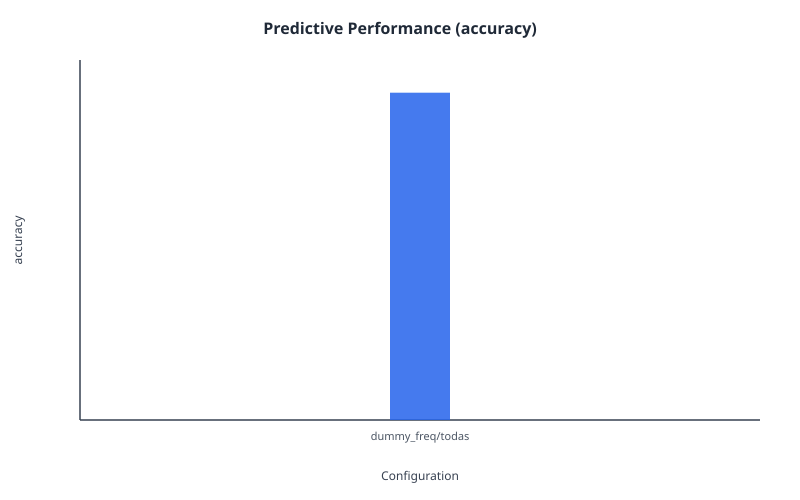

In [4]:
from experimental_ml.reporting import (
    PackageMode,
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_reproducibility_package,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_table_latex,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(exp_dir)
selection = select_report_content(
    loaded,
    ReportContentSelection(
        audience=ReportAudience.ARTICLE_COMPACT,
        families=(ReportFamily.D_PREDICTIVE_PERFORMANCE,),
    ),
)

tabela = build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, selection)
exibir_markdown("### Tabela de Desempenho\n\n" + render_table_markdown(tabela))

latex_str = render_table_latex(tabela)
print("Código LaTeX booktabs pronto para o artigo:\n")
print(latex_str)

fig_spec = build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, selection)
exibir_svg(render_figure(fig_spec, fmt="svg"))

pacote_dir = exp_dir / "pacote_conferencia"
manifest = build_reproducibility_package(
    loaded,
    output_dir=pacote_dir,
    mode=PackageMode.REDUCED_NO_RAW_DATA,
    source_experiment_dir=exp_dir,
    force=True,
)
print(f"Pacote exportado: {manifest.reproduction_level} | Arquivos: {len(manifest.exported_files)}")
checksums_preview = (pacote_dir / "reproducibility" / "checksums.sha256").read_text(encoding="utf-8").splitlines()[:5]
print("Primeiros checksums SHA-256 relativos:")
for line in checksums_preview:
    print(" ", line)